# Чекпоинт 2. Разведочный анализ цен, целевой переменной и признаков

**Задача проекта.** Мы прогнозируем цену карбамида на один и на три месяца вперёд. Цену мы раскладываем на две части: газовую составляющую, равную k × цена газа TTF, и надбавку производителя. Модель прогнозирует надбавку, а газовую составляющую мы берём из цены газа, которая уже известна на дату прогноза.

**Данные.** Ежемесячные цены World Bank Pink Sheet, 20 рядов: энергоносители, удобрения, сельскохозяйственные культуры и металлы. Торговлю по данным UN Comtrade и оборотный капитал производителей мы разбираем в ноутбуке 02_eda_external.

**Периоды.** Рабочий период начинается в апреле 2015 года, потому что только с этого месяца цена газа Европы в Pink Sheet считается по хабу TTF. Заканчивается рабочий период в сентябре 2026 года. Обучающая выборка (трейн) охватывает период с апреля 2015 по сентябрь 2023 года, это 102 месяца. Тестовая выборка (тест) охватывает период с октября 2023 по сентябрь 2026 года, это 36 месяцев. Описательные графики мы показываем на всём рабочем периоде. Все выводы о связях между рядами и выбор коэффициента k мы делаем только на трейне, чтобы тестовая выборка оставалась нетронутой до финальной проверки модели.

**Две целевые переменные.**
- target_markup: надбавка через месяц, то есть urea_price(t+1) минус k · gas_europe(t), где k = 12. Значение k = 12 обосновано в разделе 3.
- target_change: изменение цены карбамида за следующий месяц в логарифмах, то есть ln(urea(t+1) / urea(t)).

| Раздел | Содержание |
|---|---|
| 1 | Особенности данных: описательная статистика, пропуски, ошибочные значения, выбросы |
| 2 | Признаки и их связь с целевой переменной: распределения, сводные таблицы, корреляции, попарные графики, отбор признаков |
| 3 | Целевая переменная: коэффициент k по периодам и стационарность надбавки (тест ADF) |
| 4 | Как газ влияет на цену во времени: запаздывание и тест Грейнджера |
| 5 | Выводы и их использование в проекте |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.read_excel("../data/raw/CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices", header=None)

header_row = raw.index[raw.astype(str).apply(lambda r: r.str.strip().str.startswith("Urea").any(), axis=1)][0]
columns = raw.iloc[header_row].fillna("").astype(str).str.strip().str.replace(r"\s*\*+$", "", regex=True)
body = raw.iloc[header_row + 2:].copy()
body.columns = columns
body = body[body.iloc[:, 0].astype(str).str.match(r"^\d{4}M\d{2}$")]
body.index = pd.to_datetime(body.iloc[:, 0].str.replace("M", "-") + "-01")

names = {
    "Crude oil, Brent": "brent", "Coal, Australian": "coal_aus", "Coal, South African": "coal_safr",
    "Natural gas, US": "gas_us", "Natural gas, Europe": "gas_europe", "Liquefied natural gas, Japan": "lng_japan",
    "Urea": "urea_price", "DAP": "dap", "TSP": "tsp", "Phosphate rock": "phosphate_rock", "Potassium chloride": "potash",
    "Maize": "maize", "Wheat, US HRW": "wheat", "Soybeans": "soybeans", "Rice, Thai 5%": "rice",
    "Sugar, world": "sugar", "Palm oil": "palm_oil", "Copper": "copper", "Iron ore, cfr spot": "iron_ore", "Aluminum": "aluminum",
}
full = pd.DataFrame({new: pd.to_numeric(body[old].replace("…", np.nan), errors="coerce") for old, new in names.items()})

df = full.loc["2015-04":].copy()
K = 12
df["markup"] = df["urea_price"] - K * df["gas_europe"]
df["target_markup"] = df["urea_price"].shift(-1) - K * df["gas_europe"]
df["target_change"] = np.log(df["urea_price"].shift(-1) / df["urea_price"])
df["regime"] = "спокойно"
df.loc["2021-07":"2022-12", "regime"] = "кризис"
df.loc["2023-01":, "regime"] = "после кризиса"
df["regime"] = df["regime"].astype("category")

train = df.loc[:"2023-09"]
prices = list(names.values())
print("Вся история:", full.index.min().date(), "–", full.index.max().date(), len(full), "мес.")
print("Рабочий период:", df.index.min().date(), "–", df.index.max().date(), len(df), "мес.; трейн:", len(train))

Вся история: 1960-01-01 – 2026-09-01 801 мес.
Рабочий период: 2015-04-01 – 2026-09-01 138 мес.; трейн: 102


## 1. Особенности данных

### 1.1. Основные статистики
Все признаки являются ценами, то есть вещественными числами. Кроме них в таблице есть одна категориальная колонка regime, которая обозначает режим рынка: спокойный период, кризис или период после кризиса. Функция describe(include='all') показывает для числовых колонок среднее, стандартное отклонение и квантили, а для категориальной колонки показывает число уникальных значений и самое частое значение.

In [2]:
pd.set_option("display.max_columns", 30)
df.describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brent,138.0,NaN,NaN,NaN,68.515942,19.527847,23.3,54.925,67.85,80.725,120.4
coal_aus,138.0,NaN,NaN,NaN,125.413043,81.774331,49.0,72.55,105.65,139.05,430.8
coal_safr,138.0,NaN,NaN,NaN,102.35942,51.193427,48.8,73.8,92.5,105.3,302.0
gas_us,138.0,NaN,NaN,NaN,3.148188,1.355251,1.5,2.365,2.825,3.2225,8.79
gas_europe,138.0,NaN,NaN,NaN,11.813986,11.129531,1.58,5.1575,8.03,13.16,70.04
lng_japan,138.0,NaN,NaN,NaN,11.402246,3.33991,5.88,9.085,10.91,12.71,23.73
urea_price,138.0,NaN,NaN,NaN,351.663768,174.009508,142.6,233.825,286.15,394.475,925.0
dap,138.0,NaN,NaN,NaN,493.64058,175.894212,238.2,326.275,433.05,623.55,954.0
tsp,138.0,NaN,NaN,NaN,437.877536,157.390571,239.0,291.6,382.5,546.0,856.0
phosphate_rock,138.0,NaN,NaN,NaN,146.033333,78.658343,70.8,91.6,121.8,152.5,347.5


**Главный результат: у всех цен очень большой разброс, а распределения скошены вправо вследствие кризиса 2021 и 2022 годов.**

Например, цена газа Европы менялась от 1,6 до 70 долларов за миллион БТЕ, то есть в 44 раза. Средние значения у большинства рядов заметно больше медиан. Это означает, что несколько очень высоких значений кризисных лет тянут среднее вверх. Кроме того, ряды измерены в разных единицах: сахар в долларах за килограмм, нефть в долларах за баррель, остальные товары в долларах за тонну. Поэтому сравнивать ряды по уровням нельзя, и связи между ними мы дальше изучаем через корреляции и процентные изменения.

### 1.2. Пропуски
**Гипотеза.** Пропуски в Pink Sheet не означают потерянные данные. Они стоят в тех месяцах, когда ряд ещё не публиковался, и в файле такие месяцы отмечены знаком «…». Если гипотеза верна, то пропуски находятся только в начале ряда, а внутри ряда нет ни одного пропущенного месяца.

In [3]:
missing = pd.DataFrame({
    "пропусков, вся история": full.isna().sum(),
    "доля, %": (full.isna().mean() * 100).round(1),
    "первое значение": full.apply(lambda s: s.first_valid_index().date()),
    "пропусков внутри ряда": full.apply(lambda s: s.loc[s.first_valid_index():].isna().sum()),
    "пропусков с апреля 2015": full.loc["2015-04":].isna().sum(),
})
print("Доля пропусков во всей таблице 1960–2026:", round(full.isna().mean().mean() * 100, 1), "%")
missing.sort_values("доля, %", ascending=False)

Доля пропусков во всей таблице 1960–2026: 4.3 %


,"пропусков, вся история","доля, %",первое значение,пропусков внутри ряда,пропусков с апреля 2015
coal_safr,288,36.0,1984-01-01,0,0
lng_japan,204,25.5,1977-01-01,0,0
coal_aus,120,15.0,1970-01-01,0,0
dap,84,10.5,1967-01-01,0,0
brent,0,0.0,1960-01-01,0,0
wheat,0,0.0,1960-01-01,0,0
iron_ore,0,0.0,1960-01-01,0,0
copper,0,0.0,1960-01-01,0,0
palm_oil,0,0.0,1960-01-01,0,0
sugar,0,0.0,1960-01-01,0,0


**Главный результат: гипотеза подтверждается, и в рабочем периоде с апреля 2015 года пропусков нет ни в одном ряду.**

Пропуски есть только у тех рядов, публикация которых началась позже 1960 года: уголь ЮАР публикуется с 1984 года, СПГ Японии с 1977 года, уголь Австралии с 1970 года, DAP с 1967 года. Внутри рядов пропусков нет. Следовательно, датасет не разрежен, и заполнять пропуски не нужно.

**Как обрабатываем.** Мы работаем с данными начиная с апреля 2015 года, поэтому пропуски в анализ не попадают. Для будущих источников команды (PortWatch, GSCPI) мы вводим правило: пропуск можно заполнить только прошлым значением (метод ffill), не дольше чем на 2 месяца, и при этом нужно поставить флаг «был пропуск». Заполнять пропуск будущим значением (метод bfill) нельзя, потому что тогда модель получит информацию, которой на дату прогноза ещё не было, то есть произойдёт утечка данных.

### 1.3. Ошибочные значения
Мы проверяем отрицательные и нулевые цены, повторяющиеся месяцы и месяцы, пропущенные в календаре. Отдельно мы описываем смены методики расчёта цен. Такие смены не выглядят как ошибка в данных, но делают значения до и после смены несопоставимыми.

In [4]:
checks = pd.DataFrame({
    "цена ≤ 0": (df[prices] <= 0).sum(),
    "min": df[prices].min(),
    "max": df[prices].max(),
})
print("Дубли месяцев:", df.index.duplicated().sum())
expected = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Пропущенных месяцев в календаре:", len(expected.difference(df.index)))
print("Отрицательная надбавка (не ошибка, а кризисный режим), месяцев:", (df["markup"] < 0).sum())
checks.round(1)

Дубли месяцев: 0
Пропущенных месяцев в календаре: 0
Отрицательная надбавка (не ошибка, а кризисный режим), месяцев: 3


,цена ≤ 0,min,max
brent,0,23.3,120.4
coal_aus,0,49.0,430.8
coal_safr,0,48.8,302.0
gas_us,0,1.5,8.8
gas_europe,0,1.6,70.0
lng_japan,0,5.9,23.7
urea_price,0,142.6,925.0
dap,0,238.2,954.0
tsp,0,239.0,856.0
phosphate_rock,0,70.8,347.5


**Главный результат: ошибок ввода в данных нет, но в нескольких рядах менялась методика, и это нужно учитывать.**

Отрицательных и нулевых цен нет, повторяющихся месяцев нет, и в календаре нет пропущенных месяцев. Отрицательная надбавка встречается в трёх месяцах, но это не ошибка. Так бывает, когда газ в Европе становится настолько дорогим, что европейская себестоимость превышает мировую цену, а цену на рынке задают производители с дешёвым газом.

**Смены методики по описанию на листе Description файла World Bank.** Это главные причины, по которым значения ряда до и после определённой даты нельзя сравнивать напрямую.

| Ряд | Что изменилось | Как учитываем |
|---|---|---|
| Газ Европы | с апреля 2015 года это цена хаба TTF, раньше была средняя цена импорта на границе | используем период с апреля 2015 года |
| Карбамид | с марта 2022 года это цена FOB Ближний Восток, раньше была цена FOB Чёрное море | вводим флаг fob_me начиная с марта 2022 года |
| Калий (potash) | с января 2020 года это цена CFR Бразилия, раньше была цена FOB Ванкувер | учитываем при интерпретации цены калия |
| СПГ Японии | последние 2 месяца являются оценкой и потом пересматриваются | не используем последние 2 месяца |
| Пальмовое масло | в период с 2020 по 2026 год несколько раз менялась торговая площадка | в модель не берём |

### 1.4. Выбросы
Цены являются блуждающими рядами: их уровень может долго уходить вверх или вниз. Поэтому выбросы мы ищем не в уровнях цен, а в месячных изменениях, которые считаем как логарифмическую доходность. Выбросом мы называем изменение, которое отстоит от среднего значения на трейне больше чем на 3 стандартных отклонения.

Число выбросов по рядам:
gas_us            6
potash            4
phosphate_rock    4
brent             3
coal_aus          3
urea_price        3
dap               3
soybeans          2
tsp               2
coal_safr         2
lng_japan         1
gas_europe        1
wheat             1
sugar             1
palm_oil          1
copper            1
aluminum          1
urea_price : 2021-10 (+51%), 2026-03 (+43%), 2026-06 (-53%)
gas_europe : 2023-01 (-58%)
brent : 2020-03 (-51%), 2020-04 (-35%), 2026-03 (+38%)
dap : 2021-02 (+23%), 2022-03 (+23%), 2023-05 (-22%)


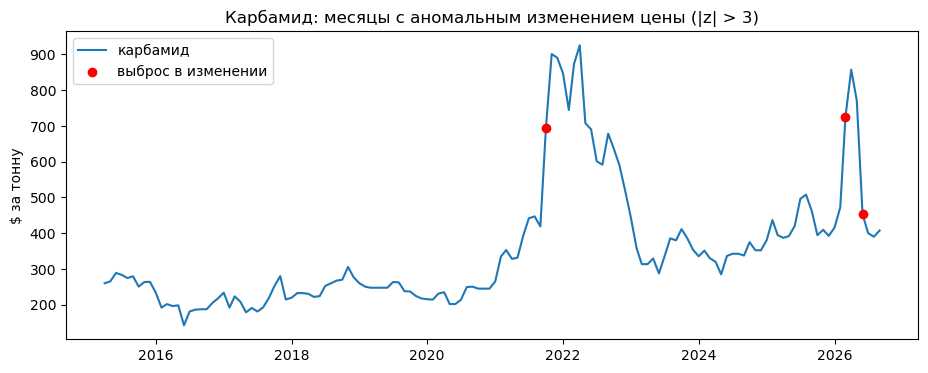

In [5]:
changes = np.log(df[prices]).diff()
z = (changes - changes.loc[:"2023-09"].mean()) / changes.loc[:"2023-09"].std()
outliers = z.abs() > 3
print("Число выбросов по рядам:")
print(outliers.sum()[outliers.sum() > 0].sort_values(ascending=False).to_string())
for col in ["urea_price", "gas_europe", "brent", "dap"]:
    months = [f"{d:%Y-%m} ({changes.loc[d, col] * 100:+.0f}%)" for d in df.index[outliers[col]]]
    print(col, ":", ", ".join(months))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df["urea_price"], label="карбамид")
ax.scatter(df.index[outliers["urea_price"]], df.loc[outliers["urea_price"], "urea_price"], color="red", zorder=3, label="выброс в изменении")
ax.set_ylabel("$ за тонну")
ax.set_title("Карбамид: месяцы с аномальным изменением цены (|z| > 3)")
ax.legend()
plt.show()

**Главный результат: все найденные выбросы являются реальными рыночными шоками, поэтому мы их не удаляем.**

У карбамида три выброса. В октябре 2021 года цена выросла на 51% вследствие газового кризиса в Европе и ограничений экспорта из Китая. В марте 2026 года цена выросла на 43% вследствие перекрытия судоходства в районе Ормузского пролива. В июне 2026 года цена упала на 53%, то есть произошло обратное движение после мартовского скачка. У нефти выбросы приходятся на март и апрель 2020 года (пандемия) и на март 2026 года. У газа Европы выброс один: в январе 2023 года цена упала на 58% после пика 2022 года.

Все выбросы связаны с реальными событиями, а не с ошибками ввода. Удалять их нельзя, потому что именно такие шоки модель и должна научиться предсказывать, а наивный прогноз ошибается сильнее всего как раз на них. **Как обрабатываем.** Мы вводим флаги режимов рынка (regime) и оцениваем качество модели отдельно в спокойные и в кризисные месяцы. Для линейных моделей в качестве варианта можно использовать функцию потерь Хьюбера, которая менее чувствительна к выбросам.

## 2. Признаки и их связь с целевой переменной

### 2.1. Распределения: уровни и изменения

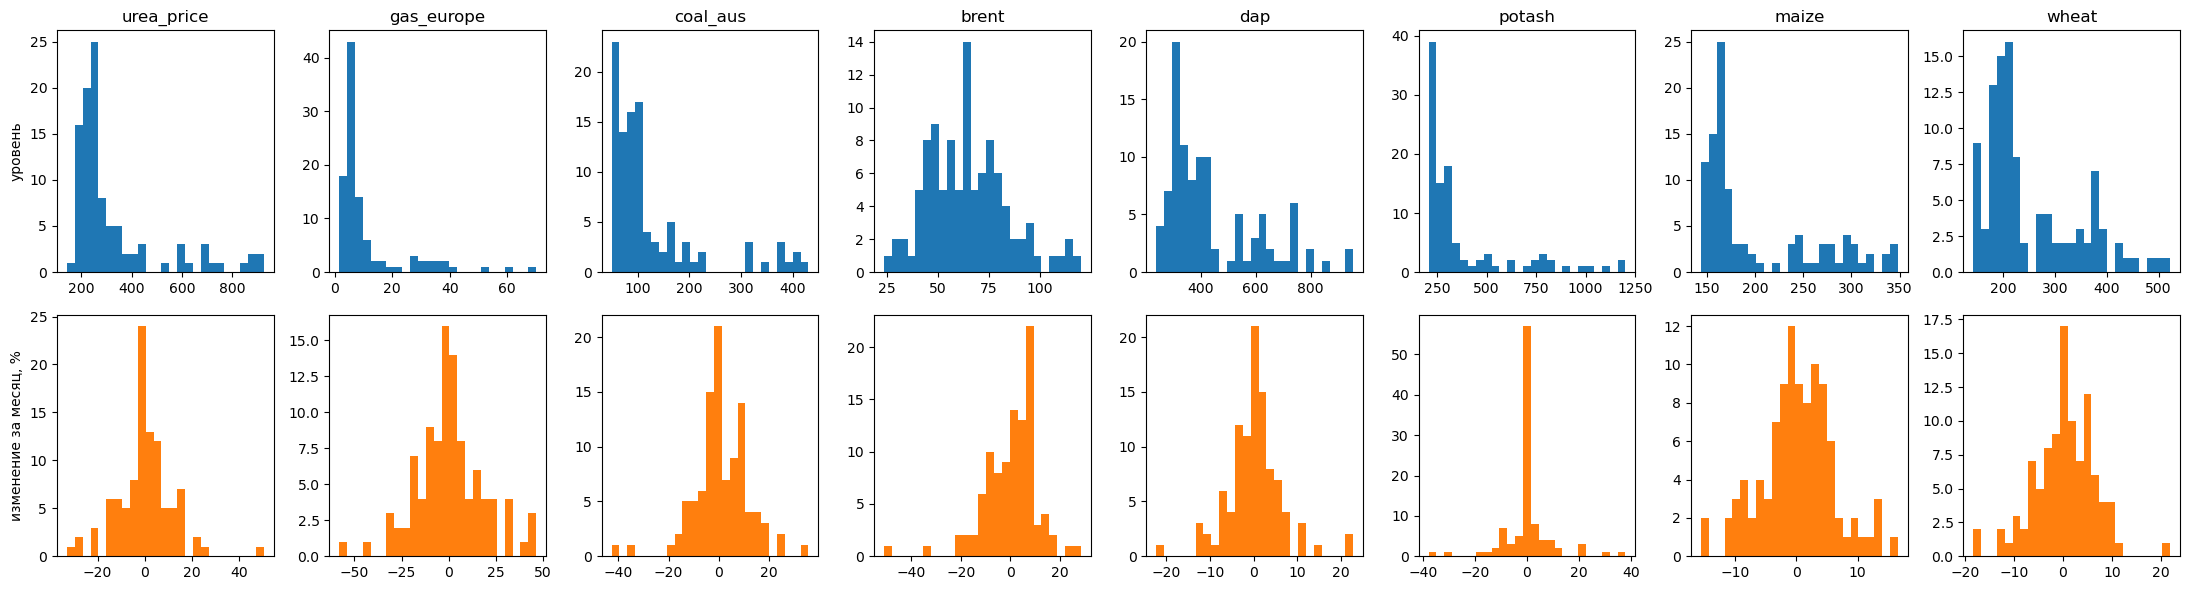

In [6]:
key = ["urea_price", "gas_europe", "coal_aus", "brent", "dap", "potash", "maize", "wheat"]
fig, axes = plt.subplots(2, len(key), figsize=(22, 6))
for i, col in enumerate(key):
    axes[0, i].hist(train[col], bins=25)
    axes[0, i].set_title(col)
    axes[1, i].hist(np.log(train[col]).diff().dropna() * 100, bins=25, color="tab:orange")
axes[0, 0].set_ylabel("уровень")
axes[1, 0].set_ylabel("изменение за месяц, %")
plt.tight_layout()
plt.show()

**Главный результат: в модель нужно брать изменения цен, а не их уровни.**

Уровни цен распределены с длинным хвостом вправо и часто имеют два пика. Один пик соответствует спокойным годам, второй пик соответствует кризису, поэтому уровни плохо подходят в качестве признаков. Месячные изменения цен распределены симметрично вокруг нуля, но у них тяжёлые хвосты, то есть крупные шоки случаются чаще, чем при нормальном распределении. Поэтому в модель мы берём изменения цен и разницы между ними.

### 2.2. Сводные таблицы
Сводные таблицы показывают медианы ключевых рядов по режимам рынка и средние значения по годам.

In [7]:
key_with_markup = key + ["markup"]
print("Медиана по режимам рынка:")
display(df.pivot_table(index="regime", values=key_with_markup, aggfunc="median", observed=True).T.round(1))
print("Среднее по годам:")
display(df[key_with_markup].groupby(df.index.year).mean().round(0))

Медиана по режимам рынка:


regime,спокойно,кризис,после кризиса
brent,55.5,90.6,80.1
coal_aus,80.0,312.4,135.1
dap,335.0,735.8,612.5
gas_europe,5.4,32.9,11.8
maize,163.6,297.4,206.5
markup,177.8,289.3,220.7
potash,245.5,788.8,352.0
urea_price,237.0,684.0,385.6
wheat,199.5,384.6,274.8


Среднее по годам:


,urea_price,gas_europe,coal_aus,brent,dap,potash,maize,wheat,markup
,,,,,,,,,
2015,270.0,6.0,57.0,52.0,410.0,301.0,168.0,193.0,195.0
2016,194.0,5.0,66.0,44.0,316.0,260.0,159.0,167.0,139.0
2017,214.0,6.0,89.0,54.0,323.0,218.0,155.0,174.0,145.0
2018,249.0,8.0,107.0,71.0,393.0,216.0,164.0,210.0,157.0
2019,245.0,5.0,78.0,64.0,306.0,256.0,170.0,202.0,188.0
2020,229.0,3.0,61.0,42.0,312.0,241.0,165.0,232.0,190.0
2021,483.0,16.0,138.0,70.0,601.0,543.0,260.0,315.0,290.0
2022,700.0,40.0,345.0,100.0,772.0,863.0,319.0,430.0,216.0
2023,358.0,13.0,173.0,83.0,550.0,383.0,253.0,340.0,201.0


**Главный результат: после кризиса цены не вернулись к уровню спокойных лет, и нормальная надбавка тоже сдвинулась вверх.**

В кризис 2021 и 2022 годов подорожало всё: медианная цена газа Европы выросла в 6 раз (с 5,4 до 32,9 доллара), уголь подорожал в 4 раза, карбамид почти в 3 раза, DAP примерно в 2 раза, калий примерно в 3 раза. После кризиса карбамид стоит около 390 долларов за тонну против 240 долларов в спокойные годы, а газ около 12 долларов против 5 долларов. Медианная надбавка при k = 12 в спокойные годы составляла около 180 долларов, а после кризиса около 220 долларов. Это означает, что нормальный уровень надбавки сдвинулся вверх. Одна из возможных причин состоит в смене котировки карбамида в 2022 году.

### 2.3. Матрица корреляций: уровни против изменений
Главная ловушка временных рядов состоит в том, что уровни всех цен растут и падают вместе вследствие общего тренда, инфляции и кризисов. Поэтому корреляции уровней получаются высокими, но почти ничего не говорят о реальных связях. Честную картину дают корреляции месячных изменений.

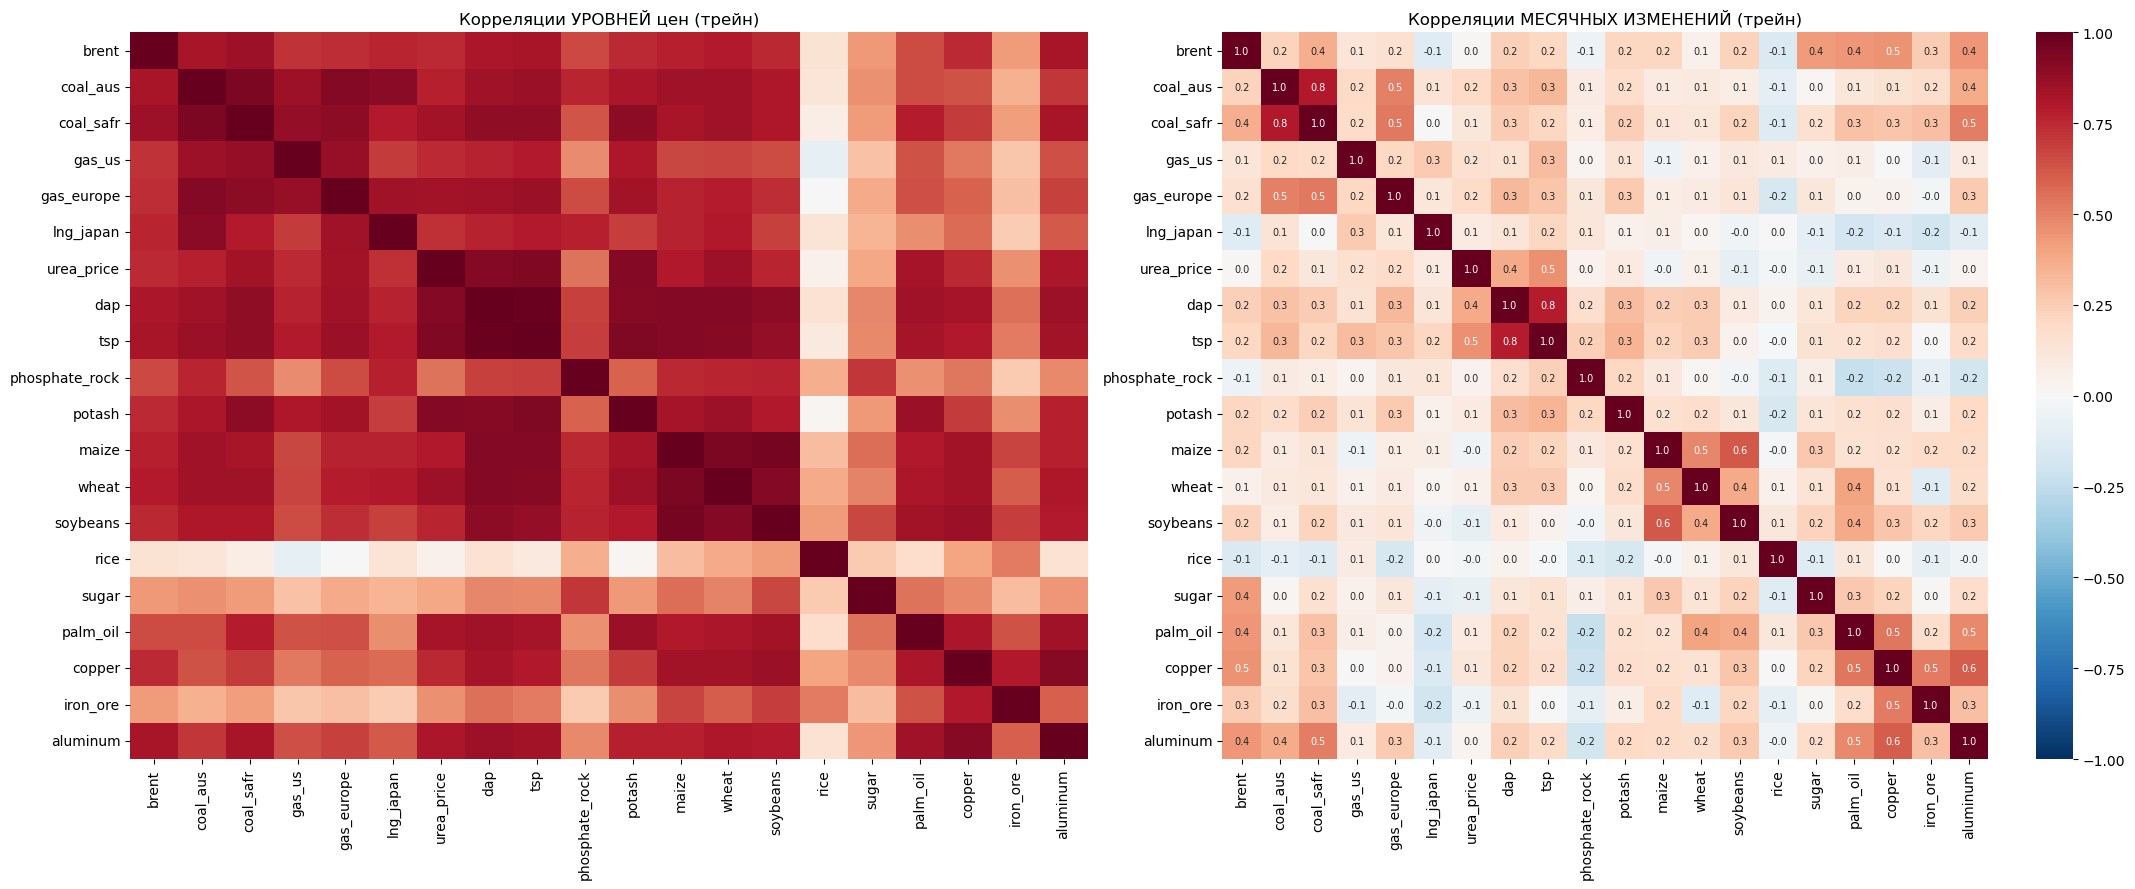

In [8]:
corr_levels = train[prices].corr()
corr_changes = np.log(train[prices]).diff().corr()

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(corr_levels, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Корреляции УРОВНЕЙ цен (трейн)")
sns.heatmap(corr_changes, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], annot=True, fmt=".1f", annot_kws={"size": 7})
axes[1].set_title("Корреляции МЕСЯЧНЫХ ИЗМЕНЕНИЙ (трейн)")
plt.tight_layout()
plt.show()

**Главный результат: в уровнях почти всё связано со всем, а в изменениях видны осмысленные группы товаров.**

Корреляции уровней находятся в диапазоне от 0,7 до 0,9 почти для всех пар. Это следствие общего тренда, а не реальной связи. В изменениях картина чище, и видны группы связанных товаров: уголь Австралии и уголь ЮАР (0,8), газ Европы и уголь (0,5), фосфорные удобрения DAP и TSP (0,8), зерновые культуры кукуруза, соя и пшеница (от 0,4 до 0,6), металлы (от 0,3 до 0,6). Изменение цены карбамида в том же месяце сильнее всего связано с изменениями цен других удобрений (DAP 0,4, TSP 0,5), а с газом и углём связано слабо (от 0,1 до 0,2). Причина в том, что газ влияет на цену карбамида с запаздыванием, и это видно в разделе 2.4.

### 2.4. Связь с целевой переменной
Мы сравниваем признак в месяце t с целевой переменной в месяце t+1, потому что только в такой постановке признак можно использовать для прогноза: на дату прогноза значение признака уже известно. Порог случайности для корреляции на трейне равен примерно 0,2 по модулю. Корреляции меньше этого порога могли получиться случайно.

In [9]:
changes_train = np.log(train[prices]).diff()
target_links = pd.DataFrame({
    "изменение сейчас → изменение цены в след. месяце": changes_train.corrwith(train["target_change"]),
    "изменение сейчас → надбавка в след. месяце": changes_train.corrwith(train["target_markup"]),
    "уровень сейчас → надбавка в след. месяце": train[prices].corrwith(train["target_markup"]),
}).round(2)
print("Порог случайности:", round(1.96 / np.sqrt(len(train) - 2), 2))
target_links.sort_values("изменение сейчас → изменение цены в след. месяце", ascending=False)

Порог случайности: 0.2


,изменение сейчас → изменение цены в след. месяце,изменение сейчас → надбавка в след. месяце,уровень сейчас → надбавка в след. месяце
gas_europe,0.38,0.11,-0.02
dap,0.31,0.32,0.33
aluminum,0.28,0.14,0.48
coal_aus,0.28,0.17,-0.06
brent,0.26,0.23,0.20
gas_us,0.25,0.15,0.02
coal_safr,0.25,0.19,0.10
copper,0.22,0.06,0.50
tsp,0.21,0.34,0.31
lng_japan,0.19,0.08,-0.06


**Главный результат: изменение цены карбамида в следующем месяце сильнее всего связано с изменением цены газа Европы в текущем месяце (корреляция 0,38).**

Следом идут изменения цен DAP (0,31), угля (0,28) и нефти (0,26). Прошлое изменение цены самого карбамида почти ничего не говорит о следующем изменении (0,08). Для надбавки следующего месяца важнее изменения цен других удобрений: калия (0,41), TSP (0,34) и DAP (0,32). Зерновые культуры связаны слабо. Высокие корреляции уровней с надбавкой (медь 0,50, пальмовое масло 0,53) объясняются общим трендом, поэтому эти уровни в признаки мы не берём. Кандидаты в признаки: изменения цен газа, угля, нефти и других удобрений за последний месяц.

### 2.5. Попарные распределения (pairplot)
На графиках показаны месячные изменения ключевых рядов и целевая переменная. Цвет точки обозначает режим рынка.

/Users/lisashtutsa/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


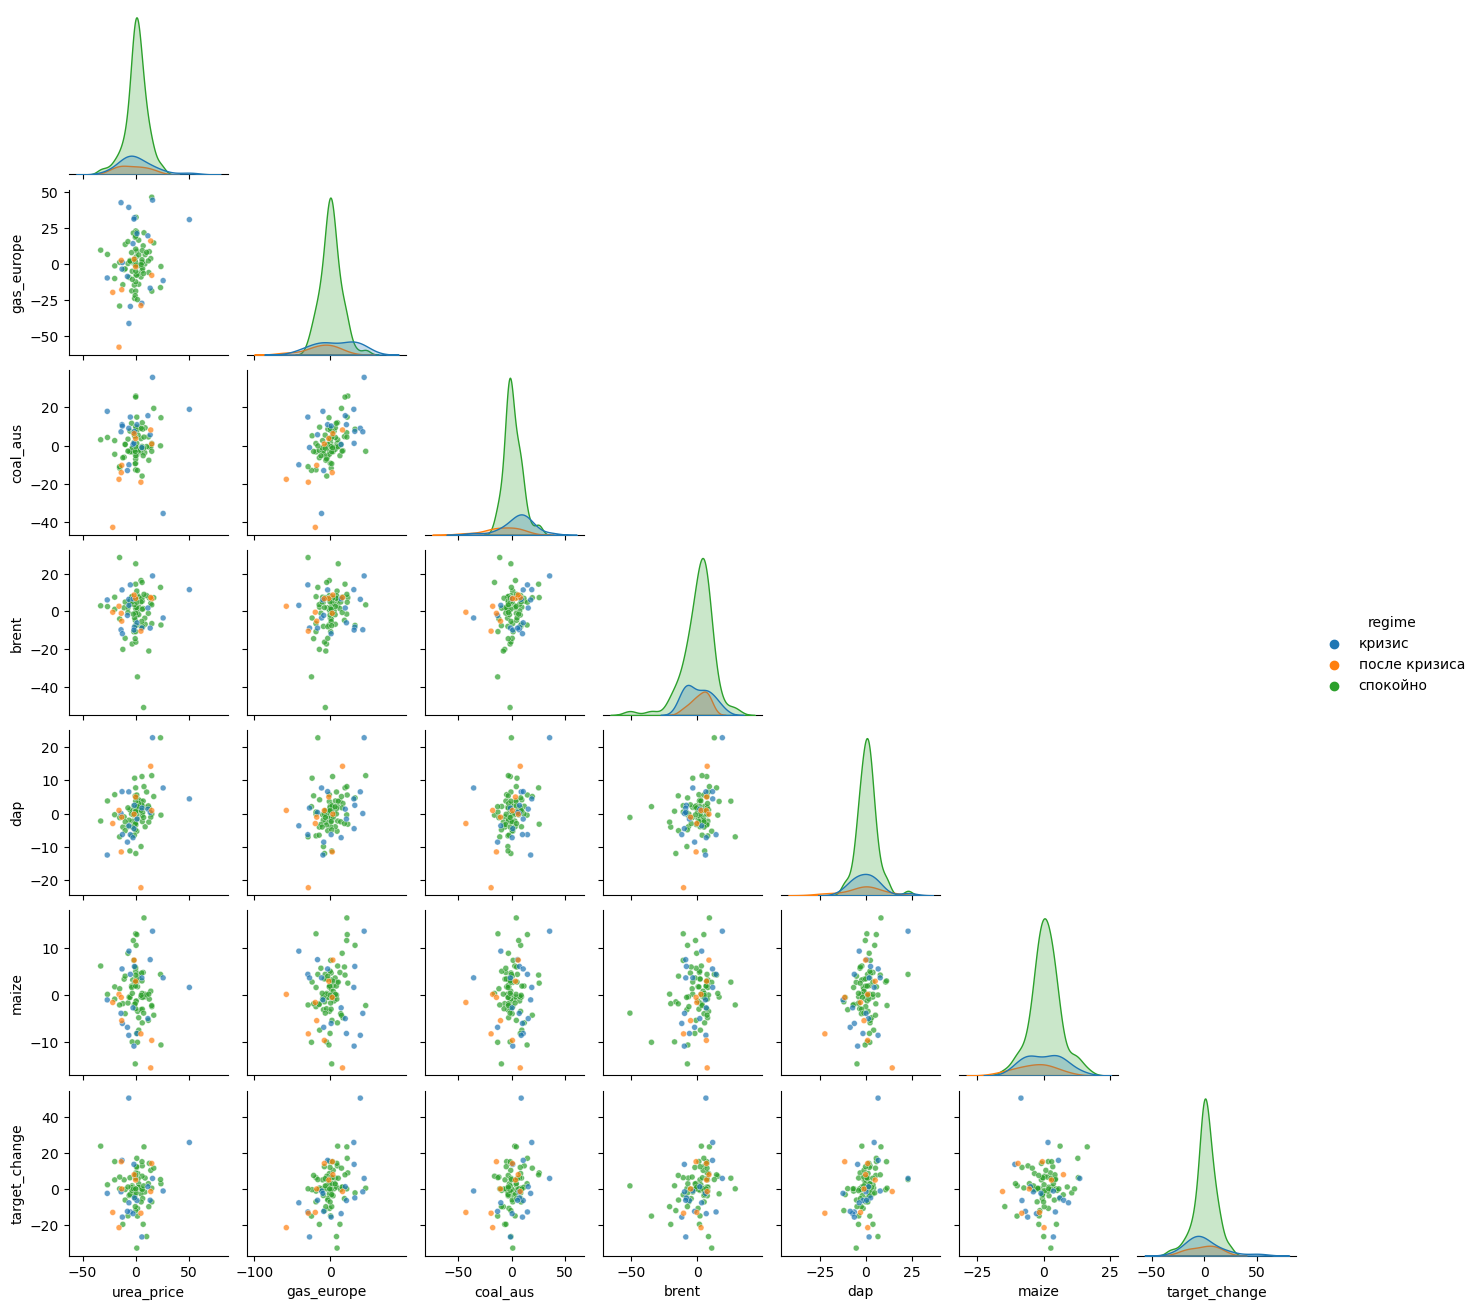

In [10]:
pair = np.log(train[["urea_price", "gas_europe", "coal_aus", "brent", "dap", "maize"]]).diff() * 100
pair["target_change"] = train["target_change"] * 100
pair["regime"] = train["regime"]
sns.pairplot(pair.dropna(), hue="regime", corner=True, plot_kws={"s": 18, "alpha": 0.7}, height=1.9)
plt.show()

**Главный результат: связи между месячными изменениями слабые, поэтому одной линейной зависимостью колебания цены не объяснить.**

Облака точек почти круглые. Наклон лучше всего виден у целевой переменной против изменения цены газа Европы и против изменения цены DAP. Кризисные месяцы дают самые крайние точки и самый большой разброс. Простая линейная связь объясняет небольшую часть колебаний цены, поэтому модели нужны признаки шоков, а качество модели мы оцениваем отдельно по режимам рынка.

### 2.6. Урезанная корреляционная матрица: отбор признаков
Из 20 рядов мы оставляем только те, которые связаны с целевой переменной, и убираем дубли. Все расчёты мы делаем на трейне, чтобы отбор не учитывал тестовую выборку.

1. **Связь с целью.** Мы оставляем признак, если модуль корреляции его изменения в текущем месяце с изменением цены карбамида в следующем месяце не меньше 0,2. Это порог случайности для 102 месяцев, рассчитанный как 1,96 / √n.
2. **Удаление дублей.** Если два оставшихся признака связаны между собой с корреляцией больше 0,75, они несут почти одну и ту же информацию. В этом случае мы оставляем тот признак, который сильнее связан с целевой переменной.

Шаг 1. Связь с целью |r| ≥ 0.2: оставлено 9 из 19
gas_europe    0.38
dap           0.31
coal_aus      0.28
aluminum      0.28
brent         0.26
coal_safr     0.25
gas_us        0.25
copper        0.22
tsp           0.21
Убраны как не связанные с целью: iron_ore, lng_japan, maize, palm_oil, phosphate_rock, potash, rice, soybeans, sugar, wheat

Шаг 2. Убраны дубли (|r| > 0.75 между признаками): coal_safr (дублирует coal_aus, r = 0.80); tsp (дублирует dap, r = 0.78)
Итог — кандидаты в признаки: gas_europe, dap, coal_aus, aluminum, brent, gas_us, copper


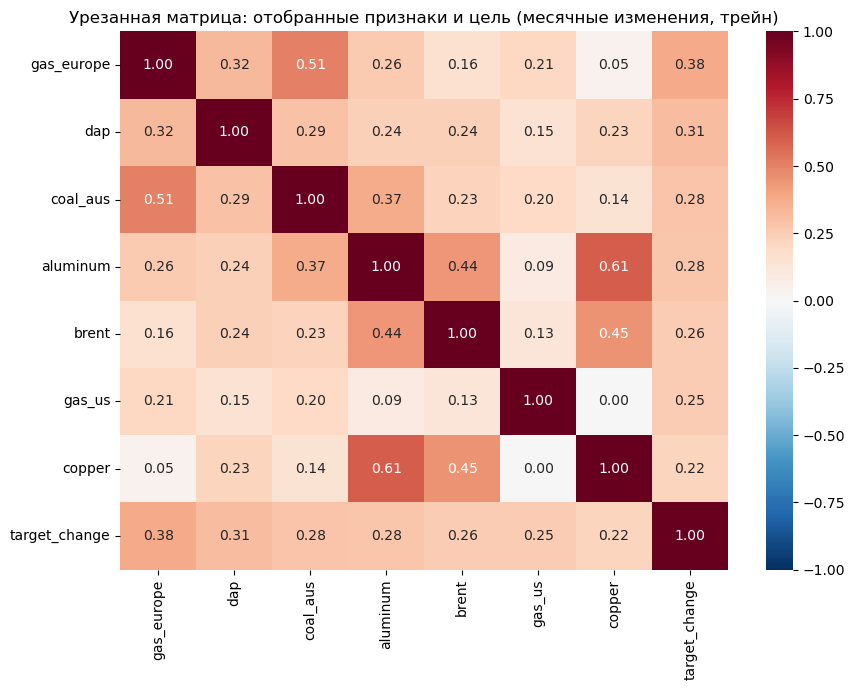

In [11]:
THRESHOLD = round(1.96 / np.sqrt(len(train) - 2), 2)
REDUNDANT = 0.75

changes_train = np.log(train[prices]).diff().drop(columns="urea_price")
link = changes_train.corrwith(train["target_change"])
step1 = link[link.abs() >= THRESHOLD].sort_values(key=abs, ascending=False)
print(f"Шаг 1. Связь с целью |r| ≥ {THRESHOLD}: оставлено {len(step1)} из {len(link)}")
print(step1.round(2).to_string())
print("Убраны как не связанные с целью:", ", ".join(link.index.difference(step1.index)))

corr_sel = changes_train[step1.index].corr()
selected, dropped = [], []
for feature in step1.index:
    twin = [s for s in selected if abs(corr_sel.loc[feature, s]) > REDUNDANT]
    if twin:
        dropped.append(f"{feature} (дублирует {twin[0]}, r = {corr_sel.loc[feature, twin[0]]:.2f})")
    else:
        selected.append(feature)
print(f"\nШаг 2. Убраны дубли (|r| > {REDUNDANT} между признаками):", "; ".join(dropped) if dropped else "нет")
print("Итог — кандидаты в признаки:", ", ".join(selected))

final = changes_train[selected].copy()
final["target_change"] = train["target_change"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(final.corr(), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Урезанная матрица: отобранные признаки и цель (месячные изменения, трейн)")
plt.tight_layout()
plt.show()

**Главный результат: после отбора остаются 7 признаков: изменения цен газа Европы, DAP, угля Австралии, алюминия, нефти Brent, газа США и меди.**

Из 19 рядов (без самого карбамида) значимо связаны с изменением цены в следующем месяце 9 рядов. Два из них мы убрали как дубли: TSP почти повторяет DAP (корреляция 0,78), а уголь ЮАР почти повторяет уголь Австралии (корреляция 0,80). Оставшиеся признаки делятся на три группы.
- **Энергоносители:** газ Европы (самая сильная связь, около 0,38), уголь Австралии, нефть Brent и газ США. Связь понятна экономически, потому что это сырьё и топливо для производства аммиака и карбамида.
- **Удобрения:** DAP. Это удобрение содержит фосфор и азот, его производят с использованием аммиака, поэтому цены DAP и карбамида меняются вместе.
- **Металлы:** алюминий и медь. Они отражают мировую промышленную активность. Экономически их связь с карбамидом объяснить труднее, поэтому мы оставляем их как кандидатов под вопросом и проверим на базовых моделях.

Как не связанные с целевой переменной убраны зерновые культуры, сахар, пальмовое масло, рис, железная руда, фосфатная руда, калий и СПГ Японии. **Оговорка.** При 19 проверках один или два признака могут пройти порог случайно. Поэтому окончательный набор признаков мы выбираем по качеству прогноза на валидации, а не только по корреляциям.

## 3. Целевая переменная: надбавка над газом и выбор k

**Зачем.** Надбавка равна цене карбамида минус k, умноженному на цену газа. Коэффициент k нужно выбрать так, чтобы надбавка возвращалась к своему нормальному уровню, то есть была стационарной. Только тогда надбавку можно прогнозировать.

В этом разделе используется подготовленная таблица data/processed/prices_monthly.parquet, которую создаёт скрипт src/data/load_pink_sheet.py.

In [12]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_parquet("../data/processed/prices_monthly.parquet")
df = df.loc["2015-04":]
train = df.loc[:"2023-09"]
print("Весь период:", df.index.min().date(), "–", df.index.max().date(), len(df), "мес.")
print("Трейн:", train.index.min().date(), "–", train.index.max().date(), len(train), "мес.")

Весь период: 2015-04-01 – 2026-09-01 138 мес.
Трейн: 2015-04-01 – 2023-09-01 102 мес.


### 3.1. Цена карбамида против TTF: k по периодам

**Зачем.** Формула выглядит так: цена равна k × газ плюс надбавка. По технологии на производство тонны карбамида уходит около 26 миллионов БТЕ газа, это расчёт Владислава. Мы проверяем на данных, какой k на самом деле закладывает рынок. Наклон линии тренда показывает, на сколько долларов дорожает тонна карбамида, когда газ дорожает на 1 доллар за миллион БТЕ. Также мы проверяем, одинаков ли этот наклон в разные периоды.

                        период  месяцев  k (наклон)  ± 95%  сдвиг, $/т   R²
 Спокойно: апр 2015 – июн 2021       75        13.0    4.6         168 0.29
   Кризис: июл 2021 – дек 2022       18         1.8    5.6         614 0.02
После кризиса: 2023 – сен 2026       45        11.4    9.2         259 0.12
    Трейн: апр 2015 – сен 2023      102        12.0    1.5         190 0.70


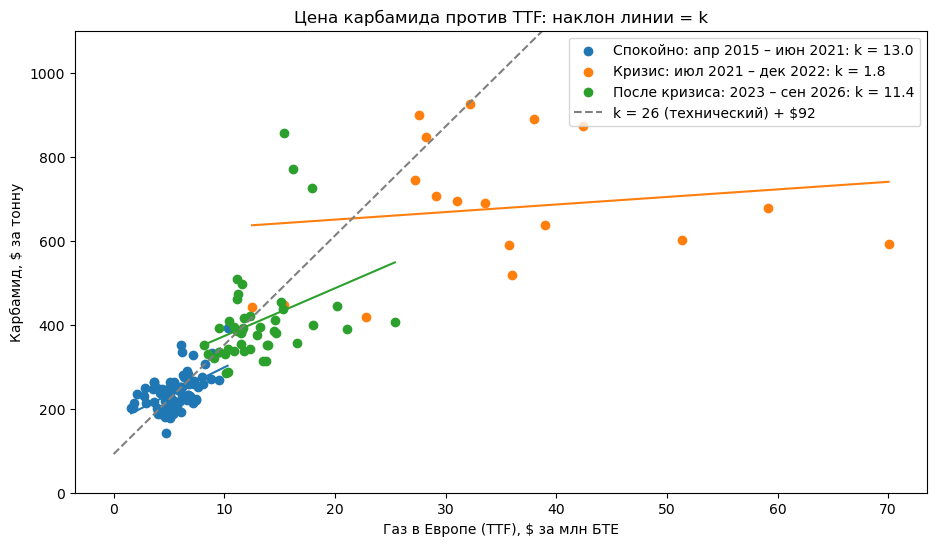

In [13]:
periods = {
    "Спокойно: апр 2015 – июн 2021": ("2015-04", "2021-06"),
    "Кризис: июл 2021 – дек 2022": ("2021-07", "2022-12"),
    "После кризиса: 2023 – сен 2026": ("2023-01", "2026-09"),
    "Трейн: апр 2015 – сен 2023": ("2015-04", "2023-09"),
}

rows = []
for name, (start, end) in periods.items():
    part = df.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    rows.append({
        "период": name,
        "месяцев": len(part),
        "k (наклон)": round(fit.slope, 1),
        "± 95%": round(1.96 * fit.stderr, 1),
        "сдвиг, $/т": round(fit.intercept),
        "R²": round(fit.rvalue ** 2, 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 6))
for name in list(periods)[:3]:
    start, end = periods[name]
    part = df.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    ax.scatter(part["gas_europe"], part["urea_price"], label=f"{name}: k = {fit.slope:.1f}")
    x = part["gas_europe"].sort_values()
    ax.plot(x, fit.intercept + fit.slope * x)
x = np.linspace(0, 40, 50)
ax.plot(x, 92 + 26 * x, color="gray", linestyle="--", label="k = 26 (технический) + $92")
ax.set_xlabel("Газ в Европе (TTF), $ за млн БТЕ")
ax.set_ylabel("Карбамид, $ за тонну")
ax.set_ylim(0, 1100)
ax.set_title("Цена карбамида против TTF: наклон линии = k")
ax.legend()
plt.show()

**Главный результат: рынок закладывает в цену k около 12, то есть вдвое меньше технических 26.**

- По данным k составляет от 12 до 13. Это означает, что цена карбамида отражает примерно половину подорожания газа, а вторую половину поглощает надбавка производителя.
- Вне кризиса k устойчив: 13,0 в период с 2015 по 2021 год и 11,4 в период с 2023 по 2026 год, и доверительные интервалы этих оценок пересекаются.
- В кризис 2021 и 2022 годов связь почти исчезает, k равен 1,8. В это время европейские заводы останавливались, а цену задавали производители с дешёвым газом. Поэтому кризис мы рассматриваем как отдельный режим.
- Для целевой переменной мы оцениваем k только на трейне и получаем 12,0 ± 1,5. Значение 11,4 рассчитано в основном по месяцам тестовой выборки, поэтому использовать его для целевой переменной нельзя.

### 3.2. Стационарность надбавки (тест ADF) для k с диаграмм

Надбавка равна цене минус k × газ. Тест ADF (тест Дики и Фуллера) проверяет, возвращается ли надбавка к своему нормальному уровню. Чем более отрицательна статистика t, тем увереннее вывод о стационарности. Порог на уровне 5% составляет около −2,89, если k задан заранее (например, k = 26 из технологии). Если же k оценён по тем же данным, порог строже и составляет около −3,37 (тест Энгла и Грейнджера).

In [14]:
from statsmodels.tsa.stattools import adfuller, coint

k_options = {
    "кризис 2021–2022": 1.8,
    "после кризиса 2023–2026": 11.4,
    "трейн целиком": 12.0,
    "спокойные 2015–2021": 13.0,
    "технический (Владислав)": 26.0,
}

rows = []
for name, k in k_options.items():
    markup = train["urea_price"] - k * train["gas_europe"]
    result = adfuller(markup, autolag="AIC")
    rows.append({
        "откуда k": name,
        "k": k,
        "ADF t": round(result[0], 2),
        "p-value": round(result[1], 3),
        "std": round(markup.std()),
        "corr с газом": round(markup.corr(train["gas_europe"]), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))
print("Порог 5%:", round(result[4]["5%"], 2))

t_stat, p_value, crit = coint(train["urea_price"], train["gas_europe"])
print("Тест Энгла–Грейнджера на трейне: t =", round(t_stat, 2), " p =", round(p_value, 3))

               откуда k    k  ADF t  p-value  std  corr с газом
       кризис 2021–2022  1.8  -1.92    0.321  164          0.79
после кризиса 2023–2026 11.4  -3.34    0.013  100          0.08
          трейн целиком 12.0  -3.50    0.008  100          0.00
    спокойные 2015–2021 13.0  -3.73    0.004  101         -0.12
технический (Владислав) 26.0  -2.86    0.050  204         -0.87
Порог 5%: -2.89
Тест Энгла–Грейнджера на трейне: t = -3.52  p = 0.03


Дополнительно мы перебираем все значения k от 0 до 30, чтобы увидеть, в каком диапазоне надбавка стационарна.

 k  ADF t  p-value  лагов  std  corr с газом
 0  -1.87    0.345      6  183          0.84
 1  -1.90    0.332      6  173          0.82
 2  -1.93    0.319      6  162          0.79
 3  -2.29    0.176      5  152          0.76
 4  -2.27    0.181      5  143          0.72
 5  -2.29    0.177      5  134          0.67
 6  -2.33    0.162      5  126          0.61
 7  -2.42    0.136      5  119          0.54
 8  -2.55    0.103      5  112          0.46
 9  -2.74    0.068      5  107          0.36
10  -2.97    0.038      5  103          0.25
11  -3.23    0.018      5  101          0.13
12  -3.50    0.008      5  100          0.00
13  -3.73    0.004      5  101         -0.12
14  -3.90    0.002      5  103         -0.24
15  -3.98    0.002      5  107         -0.36
16  -3.97    0.002      5  112         -0.45
17  -4.57    0.000      1  118         -0.54
18  -4.47    0.000      1  126         -0.61
19  -4.36    0.000      1  134         -0.67
20  -4.23    0.001      1  142         -0.71
21  -4.11 

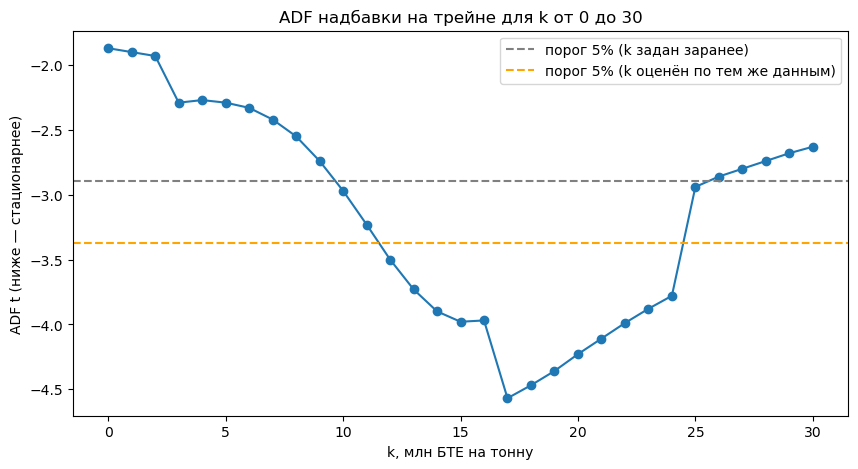

In [15]:
rows = []
for k in range(0, 31):
    markup = train["urea_price"] - k * train["gas_europe"]
    result = adfuller(markup, autolag="AIC")
    rows.append({"k": k, "ADF t": round(result[0], 2), "p-value": round(result[1], 3),
                 "лагов": result[2], "std": round(markup.std()),
                 "corr с газом": round(markup.corr(train["gas_europe"]), 2)})
table = pd.DataFrame(rows)
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(table["k"], table["ADF t"], marker="o")
ax.axhline(result[4]["5%"], color="gray", linestyle="--", label="порог 5% (k задан заранее)")
ax.axhline(-3.37, color="orange", linestyle="--", label="порог 5% (k оценён по тем же данным)")
ax.set_xlabel("k, млн БТЕ на тонну")
ax.set_ylabel("ADF t (ниже — стационарнее)")
ax.set_title("ADF надбавки на трейне для k от 0 до 30")
ax.legend()
plt.show()

**Главный результат: при k = 12 надбавка уверенно стационарна (t = −3,50), а при техническом значении k = 26 находится на границе (t = −2,86). Поэтому для целевой переменной мы берём k = 12.**

- При значениях k вне кризиса (11,4, 12,0 и 13,0) надбавка стационарна: статистика t лежит в диапазоне от −3,3 до −3,7. При этом k = 11,4 даёт t = −3,34, что находится на границе строгого порога −3,37. Разброс надбавки при таких k составляет около 100 долларов и почти не зависит от цены газа (корреляция около нуля).
- При k = 26 на трейне надбавка находится на границе значимости (t около −2,86). Кроме того, она сильно и обратно связана с ценой газа (корреляция −0,87) и в кризис опускается до −1230 долларов.
- При значении k кризисного периода (1,8) надбавка блуждает вместе с ценой газа и по сути повторяет саму цену карбамида.
- Надбавка стационарна в целом диапазоне k примерно от 12 до 24, а не в одной точке. Кривая неровная, потому что тест сам подбирает число лагов. Поэтому окончательно k мы выбираем по ошибке прогноза на валидации (extra/03_naive_backtest.ipynb), а не по самому низкому значению статистики ADF.
- Если считать тест по всему периоду вместе с тестовой выборкой, надбавка при k = 26 выглядит стационарной (p около 0,01). Однако на трейне она находится только на границе. Поэтому выводы мы делаем по трейну.

## 4. Как газ влияет на цену во времени

**Зачем.** Мы хотим понять, через сколько месяцев изменение цены газа доходит до цены карбамида и помогает ли прошлое цены газа прогнозу. Ответ обосновывает горизонт прогноза в 1 и 3 месяца и выбор запаздывающих значений цены газа в качестве признаков.

Это описательная проверка на всём рабочем периоде с апреля 2015 по сентябрь 2026 года. Количественный отбор признаков сделан только на трейне в разделе 2.6.

In [16]:
# изменения цен за месяц (лог-приращения) для разделов 4.1–4.2
prices4 = pd.read_parquet("../data/processed/prices_monthly.parquet")
prices4["r_urea"] = np.log(prices4["urea_price"]).diff()   # изменение цены карбамида за месяц
prices4["r_gas"] = np.log(prices4["gas_europe"]).diff()    # изменение цены газа Европы за месяц
s = prices4.loc["2015-04":]                                # рабочий период: с апреля 2015 (TTF)

### 4.1. С каким запаздыванием газ влияет на карбамид

**Зачем.** Мы хотим понять, через сколько месяцев изменение цены газа отражается в цене карбамида.

**Как читать график.** Столбик с номером k показывает корреляцию изменения цены карбамида в месяце t с изменением цены газа в месяце t минус k. Здесь k означает запаздывание в месяцах, а не коэффициент газа из формулы надбавки. Пунктирные линии показывают границу случайности, примерно ±2/√n. Столбики, которые выходят за эту границу, значимы.

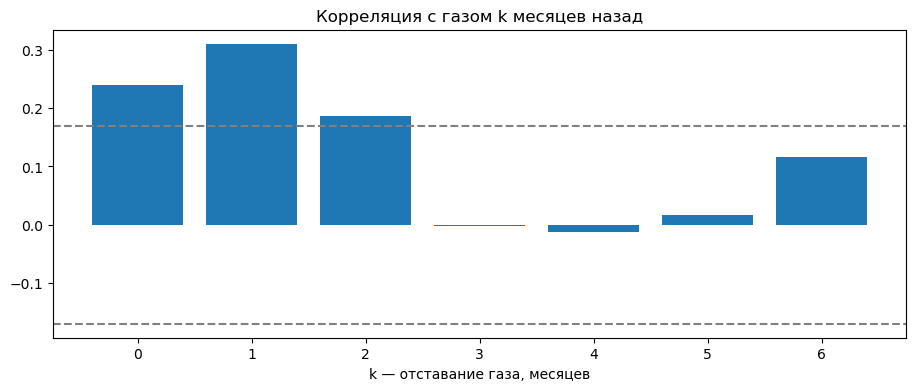

0    0.241
1    0.311
2    0.187
3   -0.002
4   -0.012
5    0.017
6    0.117
dtype: float64

In [17]:
lags = range(0, 7)
ccf = pd.Series([s["r_urea"].corr(s["r_gas"].shift(k)) for k in lags], index=list(lags))   # газ сдвинут на k месяцев назад
band = 2 / np.sqrt(s["r_urea"].notna().sum())                                             # граница случайности

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ccf.index, ccf.values)                            # столбик на каждое отставание k
ax.set_xlabel("k — отставание газа, месяцев")
ax.set_title("Корреляция с газом k месяцев назад")
ax.axhline(band, color="grey", linestyle="--")
ax.axhline(-band, color="grey", linestyle="--")
plt.show()
ccf.round(3)

**Главный результат: изменение цены газа сильнее всего отражается в цене карбамида через один месяц, а через три месяца эффект исчезает.**

Корреляции на запаздываниях 0, 1 и 2 месяца равны 0,24, 0,31 и 0,19. Все три значения выше границы случайности, которая составляет примерно 0,17. Начиная с запаздывания в 3 месяца корреляция близка к нулю. Следовательно, изменение цены газа частично отражается в цене карбамида уже в том же месяце, сильнее всего через месяц и перестаёт влиять через три месяца. Поэтому в признаки мы берём изменение цены газа за текущий месяц, за прошлый месяц и за позапрошлый месяц. Этот результат ещё раз подтверждает выбор горизонта прогноза в 1 и 3 месяца.

### 4.2. Тест Грейнджера

**Зачем.** Мы проверяем, помогает ли прошлое цены газа предсказать цену карбамида сверх того, что даёт прошлое самой цены карбамида. Также мы проверяем, что связь идёт в правильную сторону: от газа к карбамиду, а не наоборот.

**Как читать результат.** Нулевая гипотеза теста состоит в том, что прошлое второго ряда не помогает прогнозу первого ряда. Если p меньше 0,05, прошлое второго ряда помогает прогнозу. Тест проверяет не причинность в бытовом смысле, а полезность одного ряда для прогноза другого, и для нас важна именно эта полезность. Тест требует стационарных рядов, поэтому мы используем логарифмические приращения цен.

In [18]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger_p(target, cause, maxlag=6):
    data = s[[target, cause]].dropna()                   # первая колонка — что предсказываем, вторая — чем
    res = grangercausalitytests(data, maxlag=maxlag, verbose=False)
    return {lag: round(res[lag][0]["ssr_ftest"][1], 3) for lag in range(1, maxlag + 1)}

print("газ -> карбамид:", granger_p("r_urea", "r_gas"))
print("карбамид -> газ:", granger_p("r_gas", "r_urea"))   # обратная проверка: должна быть незначима

газ -> карбамид: {1: 0.001, 2: 0.001, 3: 0.001, 4: 0.005, 5: 0.011, 6: 0.002}
карбамид -> газ: {1: 0.537, 2: 0.291, 3: 0.357, 4: 0.344, 5: 0.311, 6: 0.278}


/Users/lisashtutsa/anaconda3/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1488: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/lisashtutsa/anaconda3/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1488: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


**Главный результат: прошлое цены газа помогает прогнозировать цену карбамида, а обратной связи нет.**

Для направления от газа к карбамиду значение p находится в диапазоне от 0,001 до 0,011 на всех запаздываниях от 1 до 6 месяцев, то есть связь значима. Для направления от карбамида к газу значение p находится в диапазоне от 0,28 до 0,54, то есть связи нет. Следовательно, прошлое цены газа содержит информацию о будущей цене карбамида, которой нет в прошлом самой цены карбамида. Связь односторонняя, как и должно быть по экономике: газ является сырьём для карбамида, а цена карбамида на цену газа не влияет. Этот результат обосновывает использование цены газа как признака и всю конструкцию с газовой составляющей цены.

## 5. Выводы и их использование в проекте

**Главный результат: целевая переменная (надбавка над газом при k = 12) стационарна и поэтому пригодна для прогноза. Для её прогноза отобраны 7 признаков, и сильнее всего работает изменение цены газа Европы с запаздыванием в один месяц.**

1. **Данные чистые, но неоднородные.** В рабочем периоде нет пропусков и ошибок ввода. Главные сложности связаны со сменами методики (газ Европы в 2015 году, калий в 2020 году, карбамид в 2022 году) и с кризисным режимом 2021 и 2022 годов. Поэтому мы используем период с апреля 2015 года и вводим флаги смены котировки и режима рынка.
2. **Цена карбамида блуждает, а надбавка при k около 12 стационарна.** Наклон цены карбамида по цене газа по данным составляет около 12, а не технические 26. Это означает, что цена отражает примерно половину подорожания газа. На трейне надбавка при k = 12 уверенно стационарна (статистика ADF равна −3,50), а при k = 26 находится на границе (−2,86). Окончательное значение k мы выбираем по ошибке прогноза на валидации.
3. **Выбросы являются шоками, а не ошибками.** Мы их не удаляем, а качество модели оцениваем отдельно для спокойных и кризисных месяцев.
4. **Изменение цены газа доходит до цены карбамида в течение двух месяцев.** Сильнее всего изменение цены газа связано с изменением цены карбамида через один месяц, а начиная с трёх месяцев связь пропадает. Тест Грейнджера показывает, что прошлое цены газа помогает прогнозу цены карбамида (p не больше 0,011), а обратной связи нет. Отсюда следуют горизонт прогноза в 1 и 3 месяца и использование изменений цены газа с запаздыванием до двух месяцев в качестве признаков.
5. **Корреляции уровней обманчивы, поэтому мы работаем с изменениями.** После урезания корреляционной матрицы остаются 7 кандидатов: изменения цен газа Европы, угля Австралии, нефти, газа США, DAP, алюминия и меди за последний месяц. К ним добавляются текущая надбавка, флаг режима рынка и флаг смены котировки.
6. **Наивный прогноз является сильным ориентиром.** Прогноз «цена следующего месяца равна цене текущего месяца» на месяц вперёд ошибается в среднем на 7% в спокойные месяцы и на 12% в кризис. Простые модели с одним, двумя или тремя признаками выигрывают у него вне кризиса, но проигрывают в кризис (extra/03_naive_backtest.ipynb). В строгой проверке модель Ridge с отбором признаков внутри каждого шага выигрывает на горизонте в один месяц, в том числе в кризис: её ошибка составляет 0,91 от ошибки наивного прогноза. Однако на горизонте в три месяца в кризис она проигрывает: её ошибка составляет 1,58 от ошибки наивного прогноза (extra/04_strict_validation.ipynb). Выигрыш на шоках должны дать признаки, которых нет в ценах: трафик через проливы (PortWatch), ограничения экспорта Китая и индекс давления на цепочки поставок (GSCPI).
7. **Практическая применимость.** Закупщику удобрений нужен прогноз цены на 1 и 3 месяца и понимание того, из чего складывается цена. Разложение цены на газовую составляющую и надбавку даёт и прогноз, и объяснение, и возможность считать сценарии, например «газ подорожал на 30%». Данные Pink Sheet выходят в начале следующего месяца, поэтому прогноз обновляется раз в месяц после выхода новых данных.

**Дальнейшие шаги.** Собрать единую таблицу признаков из Pink Sheet, PortWatch, GSCPI и данных о ставках в базе SQL. Затем построить базовые модели (наивный прогноз, SARIMA, линейную модель и градиентный бустинг) на общем бэктесте и сравнить их ошибку прогноза (MSPE) с ошибкой наивного прогноза отдельно по режимам рынка.